# Experiment 2: compare approaches
Read completed portable summaries only, without simulator dependencies or raw transitions. Protocols, units, histogram bins, and per-profile seed coverage must match. Native method-specific PD gains are allowed. Missing results are unavailable, never zero.


In [1]:
import json, os, sys
from pathlib import Path
import pandas as pd
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks/exp2_analysis.py").exists())
sys.path.insert(0, str(ROOT / "notebooks"))
import exp2_analysis as analysis

## Configuration
Select one loading status at a time. All discovered methods enter the main table; focused tables/curves default to PILOT, UniFP, Pos. `trial_sd` bands show equal-seed mixture standard deviation across surviving trials, not SEM. `seed_sd` instead shows sample SD across seed means. Tables always use sample SD across evaluation seeds.


In [ ]:
from b1z1_paper_names import DISPLAY_NAMES, LATEX_METHOD_NAMES
# Paper labels differ from implementation ablation numbers; task IDs stay unchanged.
CONFIG = {
    "summary_roots": [str(ROOT / "analysis/exp2")],
    "output_dir": str(ROOT / "analysis/exp2_comparison"),
    "loading": "loaded",
    "method_order": [
        "b1z1_unifp_original", "b1z1_ppo_pos",
        "b1z1_pact_ab6_position_film", "b1z1_pact_ab7_position_full",
        "b1z1_pact_ab8_coupled_film", "b1z1_pact_ab4_coupled_none",
        "b1z1_pact_ab5_coupled_concat", "b1z1_pact_ab9_representation",
        "b1z1_pact_ab10_actor", "b1z1_pact"],
    "focused_methods": ["b1z1_pact", "b1z1_unifp_original", "b1z1_ppo_pos"],
    "display_names": dict(DISPLAY_NAMES),
    "optional_metrics": [],  # e.g. torso_angular_acceleration_rms, ee_linear_acceleration_rms
    "latex_method_names": dict(LATEX_METHOD_NAMES),  # Uses the paper macros in LaTeX exports.
    "band": "trial_sd",
    "figure_size": [11, 5], 
    "font_size": 11, 
    "dpi": 200,
    "figure_title": "",  # Custom title string; None uses automatic title, empty string hides it.
    "colors": ["#0072B2", "#D55E00", "#009E73"],
}
if os.environ.get("EXP2_COMPARE_CONFIG"):
    CONFIG.update(json.loads(os.environ["EXP2_COMPARE_CONFIG"]))


Analysis helper: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/notebooks/exp2_analysis.py


pushing                                                  \
             EE [m] ↓ Velocity [m/s] ↓  Yaw [rad/s] ↓  Tracking [%] ↑   
Method                                                                  
UniFP   0.037 ± 0.000    0.051 ± 0.000  0.109 ± 0.000  92.600 ± 0.076   
Pos     0.051 ± 0.000    0.070 ± 0.000  0.074 ± 0.000  89.131 ± 0.257   
A1      0.060 ± 0.000    0.062 ± 0.000  0.070 ± 0.001  95.854 ± 0.176   
A2      0.088 ± 0.000    0.071 ± 0.001  0.093 ± 0.001  61.365 ± 0.152   
A3      0.054 ± 0.000    0.078 ± 0.000  0.078 ± 0.000  88.621 ± 0.211   
A4      0.051 ± 0.000    0.058 ± 0.000  0.068 ± 0.000  85.550 ± 0.118   
A5      0.048 ± 0.000    0.060 ± 0.000  0.067 ± 0.000  97.110 ± 0.050   
A6      0.054 ± 0.000    0.046 ± 0.000  0.074 ± 0.001  81.937 ± 0.017   
A7      0.050 ± 0.000    0.065 ± 0.000  0.122 ± 0.001  84.353 ± 0.318   
PILOT   0.039 ± 0.000    0.057 ± 0.000  0.068 ± 0.001  97.048 ± 0.035   

                             pulling                                  \
        Failure [%] ↓       EE [m] ↓ Velocity [m/s] ↓  Yaw [rad/s] ↓   
Method                                                                 
UniFP   0.000 ± 0.000  0.043 ± 0.000    0.051 ± 0.000  0.068 ± 0.000   
Pos     0.000 ± 0.000  0.057 ± 0.000    0.062 ± 0.000  0.109 ± 0.000   
A1      0.000 ± 0.000  0.121 ± 0.000    0.079 ± 0.000  0.092 ± 0.000   
A2      0.000 ± 0.000  0.088 ± 0.000    0.089 ± 0.000  0.123 ± 0.000   
A3      0.000 ± 0.000  0.087 ± 0.000    0.091 ± 0.001  0.093 ± 0.001   
A4      0.000 ± 0.000  0.076 ± 0.000    0.077 ± 0.000  0.108 ± 0.000   
A5      0.000 ± 0.000  0.060 ± 0.000    0.072 ± 0.000  0.064 ± 0.000   
A6      0.000 ± 0.000  0.060 ± 0.000    0.067 ± 0.000  0.081 ± 0.001   
A7      0.000 ± 0.000  0.041 ± 0.000    0.093 ± 0.000  0.094 ± 0.000   
PILOT   0.000 ± 0.000  0.048 ± 0.000    0.095 ± 0.000  0.068 ± 0.000   

                                            carrying                   \
        Tracking [%] ↑  Failure [%] ↓       EE [m] ↓ Velocity [m/s] ↓   
Method                                                                  
UniFP   97.697 ± 0.029  0.000 ± 0.000  0.045 ± 0.000    0.044 ± 0.000   
Pos     95.572 ± 0.119  0.000 ± 0.000  0.057 ± 0.000    0.068 ± 0.000   
A1      39.907 ± 0.114  0.000 ± 0.000  0.072 ± 0.001    0.048 ± 0.000   
A2      60.034 ± 0.224  0.000 ± 0.000  0.111 ± 0.000    0.060 ± 0.000   
A3      61.757 ± 0.496  0.000 ± 0.000  0.056 ± 0.000    0.059 ± 0.000   
A4      68.569 ± 0.070  0.000 ± 0.000  0.060 ± 0.000    0.046 ± 0.000   
A5      88.716 ± 0.064  0.000 ± 0.000  0.067 ± 0.000    0.051 ± 0.000   
A6      95.427 ± 0.200  0.000 ± 0.000  0.055 ± 0.000    0.050 ± 0.000   
A7      89.307 ± 0.153  0.000 ± 0.000  0.039 ± 0.000    0.062 ± 0.000   
PILOT   91.427 ± 0.127  0.000 ± 0.000  0.034 ± 0.000    0.063 ± 0.000   

                                                      
        Yaw [rad/s] ↓  Tracking [%] ↑  Failure [%] ↓  
Method                                                
UniFP   0.065 ± 0.000  87.492 ± 0.082  0.000 ± 0.000  
Pos     0.084 ± 0.001  82.826 ± 0.100  0.000 ± 0.000  
A1      0.071 ± 0.000  80.725 ± 0.428  0.000 ± 0.000  
A2      0.091 ± 0.000  55.477 ± 0.041  0.000 ± 0.000  
A3      0.067 ± 0.000  83.450 ± 0.033  0.000 ± 0.000  
A4      0.073 ± 0.000  79.660 ± 0.036  0.000 ± 0.000  
A5      0.070 ± 0.000  79.896 ± 0.172  0.000 ± 0.000  
A6      0.071 ± 0.000  82.881 ± 0.021  0.000 ± 0.000  
A7      0.107 ± 0.001  92.931 ± 0.108  0.000 ± 0.000  
PILOT   0.090 ± 0.001  96.869 ± 0.055  0.000 ± 0.000

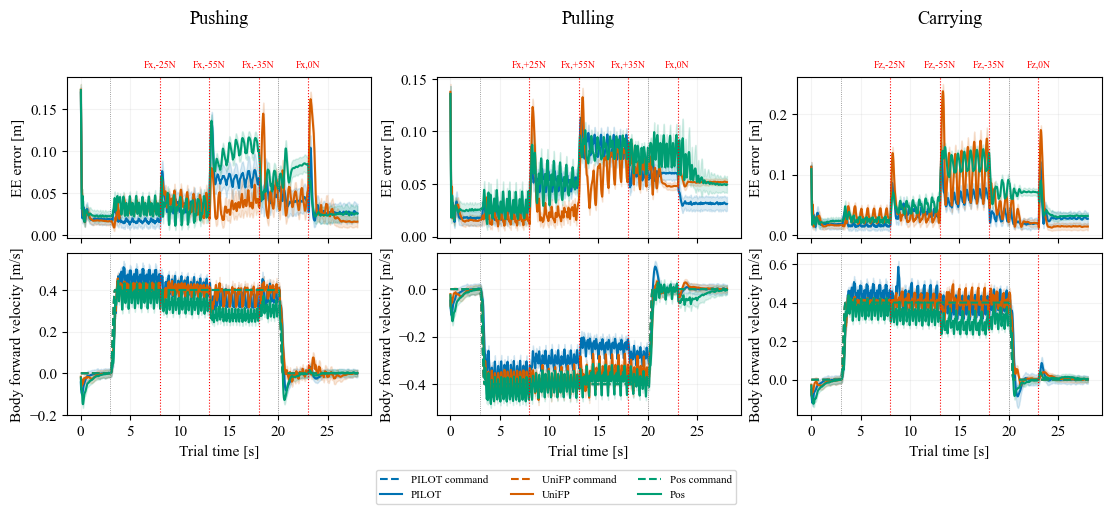

In [3]:
# Reload edited plotting code even when this notebook kernel is already running.
import importlib
analysis = importlib.reload(analysis)
print("Analysis helper:", Path(analysis.__file__).resolve())
tables, figure, diagnostics = analysis.compare(CONFIG)
display(tables["main"])


## Focused physical limits and disturbance response
Percentages are converted once for display; CSV statistics retain their explicit units. Recovery times exclude unrecovered events. Complete windows alone contribute comparable peaks. CSV/LaTeX exports preserve unavailable results.


In [4]:
display(tables["physical_limits"])
display(tables["response"])


Saturation [%] ↓ Position [%] ↓ Velocity [%] ↓
Method Profile                                                
PILOT  pushing     0.000 ± 0.000  0.000 ± 0.000  0.000 ± 0.000
       pulling     0.000 ± 0.000  0.000 ± 0.000  0.000 ± 0.000
       carrying    0.000 ± 0.000  0.417 ± 0.004  0.000 ± 0.000
UniFP  pushing     0.022 ± 0.000  0.000 ± 0.000  0.000 ± 0.000
       pulling     0.002 ± 0.000  0.000 ± 0.000  0.000 ± 0.000
       carrying    0.023 ± 0.000  0.020 ± 0.001  0.000 ± 0.000
Pos    pushing     0.000 ± 0.000  0.000 ± 0.000  0.000 ± 0.000
       pulling     0.000 ± 0.000  0.000 ± 0.000  0.000 ± 0.000
       carrying    0.000 ± 0.000  0.000 ± 0.000  0.000 ± 0.000

Peak EE [m] ↓ Recovery [s] ↓  Recovered [%] ↑  \
Method Profile                                                   
PILOT  pushing   0.103 ± 0.000  0.177 ± 0.005  100.000 ± 0.000   
       pulling   0.088 ± 0.000  0.202 ± 0.024   83.833 ± 1.258   
       carrying  0.104 ± 0.001  0.218 ± 0.016   99.500 ± 0.500   
UniFP  pushing   0.114 ± 0.001  0.455 ± 0.014   97.833 ± 0.577   
       pulling   0.104 ± 0.000  0.267 ± 0.002  100.000 ± 0.000   
       carrying  0.160 ± 0.001  0.291 ± 0.006   75.000 ± 0.000   
Pos    pushing   0.099 ± 0.000  0.137 ± 0.005   98.500 ± 1.323   
       pulling   0.099 ± 0.000  0.274 ± 0.030   94.500 ± 1.323   
       carrying  0.113 ± 0.000  0.083 ± 0.012   75.000 ± 0.000   

                EE recovered [%] ↑ Velocity recovered [%] ↑  
Method Profile                                               
PILOT  pushing     100.000 ± 0.000          100.000 ± 0.000  
       pulling      99.167 ± 0.764           88.167 ± 1.155  
       carrying    100.000 ± 0.000          100.000 ± 0.000  
UniFP  pushing     100.000 ± 0.000           98.333 ± 0.289  
       pulling     100.000 ± 0.000          100.000 ± 0.000  
       carrying     75.000 ± 0.000          100.000 ± 0.000  
Pos    pushing      99.000 ± 0.866          100.000 ± 0.000  
       pulling     100.000 ± 0.000           98.667 ± 0.289  
       carrying     75.000 ± 0.000          100.000 ± 0.000

## Task response
The two rows show EE error and body-forward command/measured velocity at successor timestamps. Horizontal labels above the top row show signed recorded Fx (initial-heading frame) or Fz (world frame) magnitudes in N, without an equals separator. Red vertical lines mark load changes in both rows; gray lines mark motion onset/stopping. No interpolation or zero-padding after failure. Signed load curves and survivor counts remain in task_response.csv, without count labels on the figure.


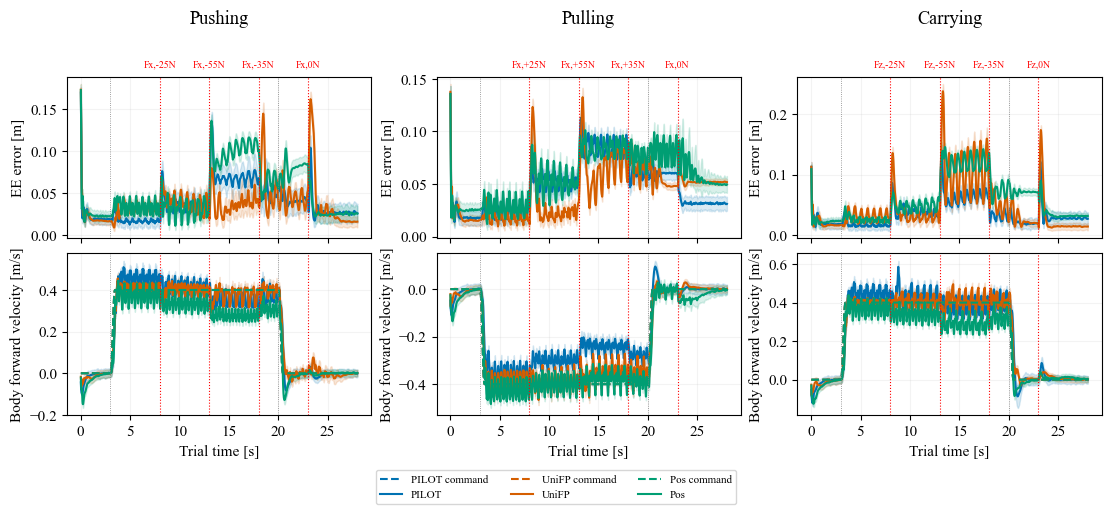

PILOT/pushing: surviving EE trials 150..150 (counts exported)
UniFP/pushing: surviving EE trials 150..150 (counts exported)
Pos/pushing: surviving EE trials 150..150 (counts exported)
PILOT/pulling: surviving EE trials 150..150 (counts exported)
UniFP/pulling: surviving EE trials 150..150 (counts exported)
Pos/pulling: surviving EE trials 150..150 (counts exported)
PILOT/carrying: surviving EE trials 150..150 (counts exported)
UniFP/carrying: surviving EE trials 150..150 (counts exported)
Pos/carrying: surviving EE trials 150..150 (counts exported)
CSV/LaTeX tables and PDF/PNG figure: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/analysis/exp2_comparison


In [5]:
display(figure)
print("\n".join(diagnostics) or "No missing-data diagnostics.")
print("CSV/LaTeX tables and PDF/PNG figure:", CONFIG["output_dir"])
